In [102]:
# ==== 基础依赖 ====
# 如果第一次用，可以先在环境里 pip 一下：
# !pip install tensorboard

import os
import glob
from tensorboard.backend.event_processing import event_accumulator
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

# 使用 seaborn style（如果可用）
try:
    plt.style.use("seaborn-v0_8")
except:
    try:
        plt.style.use("seaborn")
    except:
        pass

# ==== 自动检测项目根目录 ====
# 当前工作目录通常是项目根目录
PROJECT_ROOT = os.path.dirname(os.path.abspath(""))
# Minigrid 的结果位于 results 目录下
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
# Minigrid 的日志位于 boundary_ns_rl/logs 目录下
LOGS_DIR = os.path.join(PROJECT_ROOT, "boundary_ns_rl", "logs")

# ==== 加载 Minigrid 训练结果（从 .npy 文件） ====
# 使用最新的训练结果文件
DATA_FILES = {
    "PPO": os.path.join(RESULTS_DIR, "ppo", "minigrid_ppo_stats_20251201_180210.npy"),
    "PPO+RND": os.path.join(RESULTS_DIR, "rnd", "minigrid_rnd_stats_20251201_153128.npy"),
    "PPO+ICM": os.path.join(RESULTS_DIR, "icm", "minigrid_icm_stats_20251201_150231.npy"),
}

# 检查哪些文件存在
existing_data = {}
for name, path in DATA_FILES.items():
    if os.path.isfile(path):
        existing_data[name] = path
        print(f"  ✓ 找到: {name} at {path}")
    else:
        print(f"  ✗ 未找到: {name} at {path}")

print(f"\n找到 {len(existing_data)} 个数据文件")

# 加载数据
DATA = {}
for name, path in existing_data.items():
    try:
        data = np.load(path, allow_pickle=True).item()
        DATA[name] = data
        print(f"  ✓ 成功加载: {name}")
    except Exception as e:
        print(f"  ✗ 加载失败: {name} - {e}")

print(f"\n成功加载 {len(DATA)} 个数据集")

# ==== 辅助函数：从 TensorBoard 加载数据 ====
def load_scalar_from_event(run_dir, tag, silent=False):
    """从 TensorBoard run 目录中读取指定 tag 的 scalar 序列"""
    if not os.path.isdir(run_dir):
        if not silent:
            print(f"[WARN] Run dir not found: {run_dir}")
        return None, None
    
    ea = event_accumulator.EventAccumulator(
        run_dir,
        size_guidance={"scalars": 0}
    )
    ea.Reload()
    
    available = ea.Tags().get("scalars", [])
    if tag not in available:
        if not silent:
            print(f"[WARN] tag '{tag}' not found in {run_dir}")
        return None, None
    
    events = ea.Scalars(tag)
    steps = np.array([e.step for e in events])
    values = np.array([e.value for e in events])
    return steps, values

def load_tensorboard_data(tensorboard_dir, name, total_training_steps=20000):
    """从 TensorBoard 目录加载数据并转换为与 .npy 文件相同的格式
    
    Args:
        tensorboard_dir: TensorBoard 日志目录
        name: 数据集名称
        total_training_steps: 总训练步数（用于将 episode 数据转换为 step 数据）
    """
    if not os.path.isdir(tensorboard_dir):
        print(f"  ✗ 未找到 {name} TensorBoard 日志: {tensorboard_dir}")
        return None
    
    print(f"\n  ✓ 找到 {name} TensorBoard 日志: {tensorboard_dir}")
    
    # 加载各种指标
    external_steps, external_vals = load_scalar_from_event(tensorboard_dir, "rollout/episode_external_reward", silent=True)
    intrinsic_steps, intrinsic_vals = load_scalar_from_event(tensorboard_dir, "rollout/episode_intrinsic_reward", silent=True)
    total_steps, total_vals = load_scalar_from_event(tensorboard_dir, "rollout/total_reward_cumulative", silent=True)
    
    if external_vals is None or len(external_vals) == 0:
        print(f"  ✗ 无法加载 {name} 数据: 未找到有效的 episode_external_reward")
        return None
    
    # 将 TensorBoard 数据转换为与 .npy 文件相同的格式
    tb_data = {
        "episode_rewards": external_vals,
        "episode_intrinsic": intrinsic_vals if intrinsic_vals is not None and len(intrinsic_vals) > 0 else np.zeros_like(external_vals),
        "episode_lengths": None,  # TensorBoard 日志中可能没有这个
        "all_step_rewards": None,
    }
    
    # 关键：将 episode 数据转换为 step 数据
    # external_steps 包含每个 episode 结束时的 step 数
    if external_steps is not None and len(external_steps) > 0:
        # 计算每个 episode 的长度
        episode_lengths = np.diff(external_steps, prepend=0)
        # 第一个 episode 从 step 0 开始
        if len(external_steps) > 0:
            episode_lengths[0] = external_steps[0] + 1
        
        # 创建 step-level 的 rewards 数组
        step_rewards = np.zeros(total_training_steps)
        step_intrinsic = np.zeros(total_training_steps)
        
        # 将每个 episode 的 reward 分配到对应的 steps
        current_step = 0
        for i in range(len(external_vals)):
            ep_length = int(episode_lengths[i])
            # 确保不超过总步数
            if current_step >= total_training_steps:
                break
            end_step = min(current_step + ep_length, total_training_steps)
            actual_length = end_step - current_step
            
            if actual_length > 0:
                # 将 episode reward 平均分配到该 episode 的所有 steps
                step_rewards[current_step:end_step] = external_vals[i] / actual_length
                if intrinsic_vals is not None and i < len(intrinsic_vals):
                    step_intrinsic[current_step:end_step] = intrinsic_vals[i] / actual_length
            
            current_step = end_step
        
        tb_data["all_step_rewards"] = step_rewards
        tb_data["step_intrinsic"] = step_intrinsic
        tb_data["Total Rewards"] = np.cumsum(step_rewards)
    else:
        # 如果没有 step 信息，使用简单的方法
        # 假设所有 episodes 平均分配总步数
        n_episodes = len(external_vals)
        if n_episodes > 0:
            steps_per_episode = total_training_steps // n_episodes
            step_rewards = np.zeros(total_training_steps)
            step_intrinsic = np.zeros(total_training_steps)
            
            for i in range(n_episodes):
                start_step = i * steps_per_episode
                end_step = min((i + 1) * steps_per_episode, total_training_steps)
                if end_step > start_step:
                    step_rewards[start_step:end_step] = external_vals[i] / (end_step - start_step)
                    if intrinsic_vals is not None and i < len(intrinsic_vals):
                        step_intrinsic[start_step:end_step] = intrinsic_vals[i] / (end_step - start_step)
            
            tb_data["all_step_rewards"] = step_rewards
            tb_data["step_intrinsic"] = step_intrinsic
            tb_data["Total Rewards"] = np.cumsum(step_rewards)
        else:
            tb_data["all_step_rewards"] = np.zeros(total_training_steps)
            tb_data["step_intrinsic"] = np.zeros(total_training_steps)
            tb_data["Total Rewards"] = np.zeros(total_training_steps)
    
    print(f"    - Episode External Rewards: {len(external_vals)} 个数据点")
    print(f"    - Step Rewards: {len(tb_data['all_step_rewards'])} 个数据点")
    if intrinsic_vals is not None and len(intrinsic_vals) > 0:
        print(f"    - Episode Intrinsic Rewards: {len(intrinsic_vals)} 个数据点")
    
    return tb_data

# ==== 加载 NS 训练结果（从 TensorBoard 日志） ====
NS_TENSORBOARD_DIR = os.path.join(LOGS_DIR, "minigrid_ppo_ns", "PPO_9")
ns_data = load_tensorboard_data(NS_TENSORBOARD_DIR, "PPO+NS", total_training_steps=20000)
if ns_data is not None:
    DATA["PPO+Novelty Search"] = ns_data
    print(f"  ✓ 成功加载: PPO+NS")

# ==== 加载 BANS 训练结果（从 TensorBoard 日志） ====
BANS_TENSORBOARD_DIR = os.path.join(LOGS_DIR, "minigrid_ppo_bans", "PPO_7")
bans_data = load_tensorboard_data(BANS_TENSORBOARD_DIR, "PPO+BANS", total_training_steps=20000)
if bans_data is not None:
    DATA["PPO+Boundary-Aware Novelty Search"] = bans_data
    print(f"  ✓ 成功加载: PPO+BANS")

print(f"\n总共加载 {len(DATA)} 个数据集: {', '.join(DATA.keys())}")


  ✓ 找到: PPO at /Users/songxiaodao/Desktop/CSE 5100/Project/CSE5100-Project/results/ppo/minigrid_ppo_stats_20251201_180210.npy
  ✓ 找到: PPO+RND at /Users/songxiaodao/Desktop/CSE 5100/Project/CSE5100-Project/results/rnd/minigrid_rnd_stats_20251201_153128.npy
  ✓ 找到: PPO+ICM at /Users/songxiaodao/Desktop/CSE 5100/Project/CSE5100-Project/results/icm/minigrid_icm_stats_20251201_150231.npy

找到 3 个数据文件
  ✓ 成功加载: PPO
  ✓ 成功加载: PPO+RND
  ✓ 成功加载: PPO+ICM

成功加载 3 个数据集

  ✓ 找到 PPO+NS TensorBoard 日志: /Users/songxiaodao/Desktop/CSE 5100/Project/CSE5100-Project/boundary_ns_rl/logs/minigrid_ppo_ns/PPO_9
    - Episode External Rewards: 12 个数据点
    - Step Rewards: 20000 个数据点
    - Episode Intrinsic Rewards: 12 个数据点
  ✓ 成功加载: PPO+NS

  ✓ 找到 PPO+BANS TensorBoard 日志: /Users/songxiaodao/Desktop/CSE 5100/Project/CSE5100-Project/boundary_ns_rl/logs/minigrid_ppo_bans/PPO_7
    - Episode External Rewards: 12 个数据点
    - Step Rewards: 20000 个数据点
    - Episode Intrinsic Rewards: 12 个数据点
  ✓ 成功加载: PPO+BANS

总共加载 5 个

In [103]:
# ===== 查看所有可用的数据字段 =====
if len(DATA) > 0:
    first_name = list(DATA.keys())[0]
    first_data = DATA[first_name]
    print(f"数据集 '{first_name}' 包含的字段:")
    print("=" * 60)
    for key in sorted(first_data.keys()):
        value = first_data[key]
        if isinstance(value, np.ndarray):
            print(f"  - {key}: shape={value.shape}, dtype={value.dtype}")
        else:
            print(f"  - {key}: {type(value).__name__}")
    print("=" * 60)
    
    # 检查每个数据集都有哪些字段
    print("\n各数据集包含的字段:")
    print("-" * 60)
    for name, data in DATA.items():
        print(f"\n{name}:")
        for key in sorted(data.keys()):
            value = data[key]
            if isinstance(value, np.ndarray):
                print(f"  - {key}: shape={value.shape}")
            else:
                print(f"  - {key}: {type(value).__name__}")
    print("-" * 60)


数据集 'PPO' 包含的字段:
  - Total Rewards: shape=(206,), dtype=float64
  - all_step_rewards: shape=(20000,), dtype=float64
  - episode_intrinsic: shape=(206,), dtype=float64
  - episode_lengths: shape=(206,), dtype=int64
  - episode_rewards: shape=(206,), dtype=float64
  - rewarded_steps: shape=(181,), dtype=float64

各数据集包含的字段:
------------------------------------------------------------

PPO:
  - Total Rewards: shape=(206,)
  - all_step_rewards: shape=(20000,)
  - episode_intrinsic: shape=(206,)
  - episode_lengths: shape=(206,)
  - episode_rewards: shape=(206,)
  - rewarded_steps: shape=(181,)

PPO+RND:
  - Total Rewards: shape=(253,)
  - all_step_rewards: shape=(20000,)
  - episode_intrinsic: shape=(253,)
  - episode_lengths: shape=(253,)
  - episode_rewards: shape=(253,)
  - rewarded_steps: shape=(20000,)

PPO+ICM:
  - Total Rewards: shape=(336,)
  - all_step_rewards: shape=(20000,)
  - episode_intrinsic: shape=(336,)
  - episode_lengths: shape=(336,)
  - episode_rewards: shape=(336,)

PP

In [104]:
# 固定颜色映射，便于区分曲线
color_map = {
    "PPO": "tab:blue",
    "PPO+RND": "tab:orange",
    "PPO+ICM": "tab:green",
    "PPO+Novelty Search": "gold",
    "PPO+Boundary-Aware Novelty Search": "tab:purple",
}

def get_data_field(data_dict, field_name, default=None):
    """
    从数据字典中获取指定字段，支持多种可能的字段名。
    """
    # 尝试直接匹配
    if field_name in data_dict:
        return data_dict[field_name]
    
    # 尝试其他可能的字段名
    alternatives = {
        "episode_rewards": ["episode_rewards", "ep_rewards", "rewards"],
        "episode_intrinsic": ["episode_intrinsic", "episode_intrinsic_reward", "intrinsic_rewards"],
        "episode_lengths": ["episode_lengths", "ep_lengths", "lengths"],
        "step_rewards": ["all_step_rewards", "rewarded_steps", "Total Rewards", "step_rewards"],
    }
    
    if field_name in alternatives:
        for alt in alternatives[field_name]:
            if alt in data_dict:
                return data_dict[alt]
    
    return default

def plot_comparison(metric_name, data_dict, title=None, xlabel="Episode", ylabel=None):
    """
    在一张图上绘制多个数据集的同一个指标对比。
    """
    plt.figure(figsize=(10, 6))
    
    for name, data in data_dict.items():
        values = get_data_field(data, metric_name)
        if values is None:
            print(f"[WARN] {name} 中没有找到字段: {metric_name}")
            continue
        
        # 转换为 numpy array
        if not isinstance(values, np.ndarray):
            values = np.array(values)
        
        # x 轴：episode 编号
        x_data = np.arange(1, len(values) + 1)
        
        color = color_map.get(name, None)
        plt.plot(x_data, values, label=name, linewidth=1.5, alpha=0.8, color=color)
    
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.xlabel(xlabel, fontsize=12)
    plt.ylabel(ylabel if ylabel is not None else metric_name, fontsize=12)
    plt.title(title if title is not None else metric_name, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()



绘制对比图: PPO, PPO+RND, PPO+ICM, PPO+Novelty Search, PPO+Boundary-Aware Novelty Search

绘制 MiniGrid-DoorKey-5x5: Episode External Rewards...


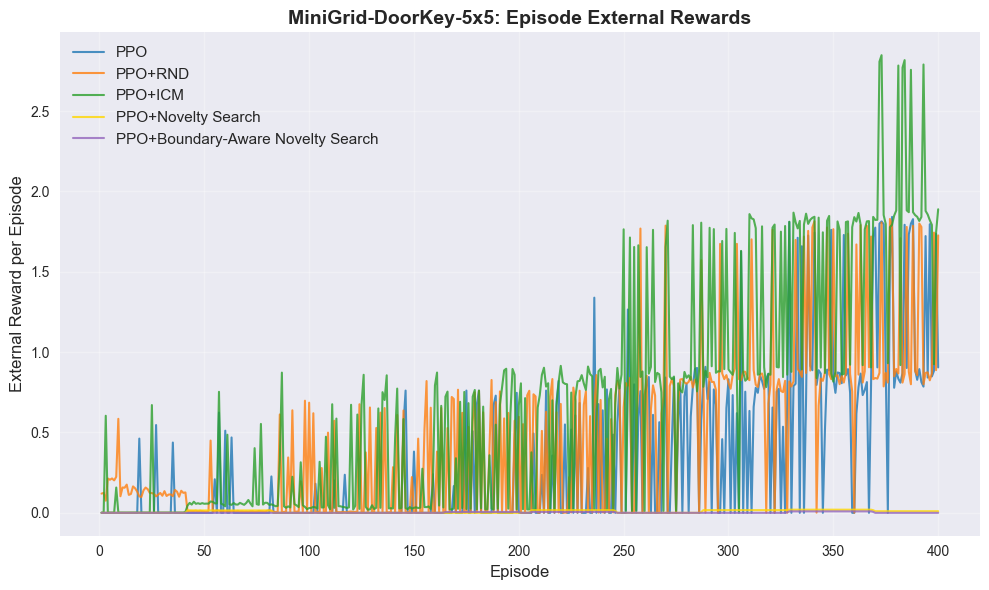


绘制 MiniGrid-DoorKey-5x5: Episode Intrinsic Rewards...


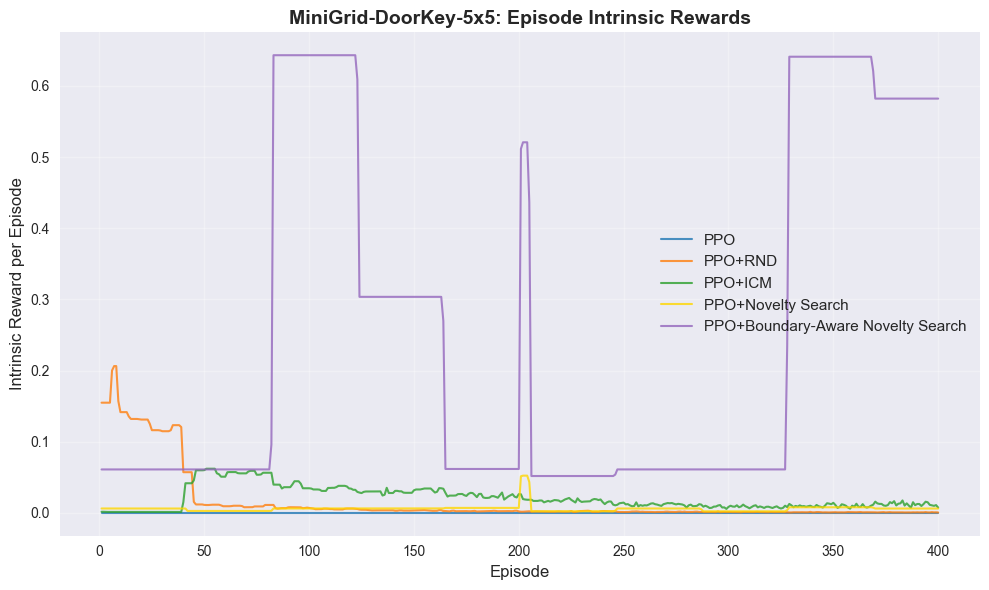


绘制 Total Reward (Cumulative)...


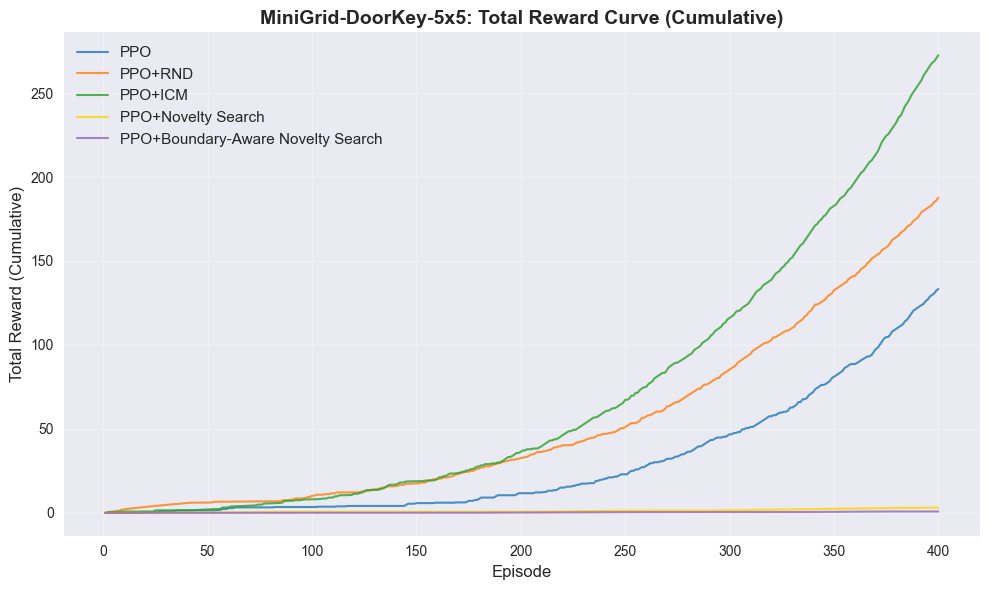

In [105]:
# ===== 对比图：PPO, PPO+RND, PPO+ICM, PPO+NS, PPO+BANS =====
# 使用从 .npy 文件加载的数据（baseline）和从 TensorBoard 日志加载的数据（NS, BANS）

if len(DATA) > 0:
    print("\n" + "=" * 60)
    print(f"绘制对比图: {', '.join(DATA.keys())}")
    print("=" * 60)
    
    # ===== 将 step 数据转换为固定大小的 episode 数据（50 steps/episode）=====
    # 这样可以让图表更平滑，更容易看清趋势
    
    def convert_steps_to_episodes(step_data, steps_per_episode=50):
        """
        将 step-level 数据转换为固定大小的 episode 数据
        
        Args:
            step_data: step-level 数据数组
            steps_per_episode: 每个 episode 包含的 steps 数（默认 50）
        
        Returns:
            episode_data: episode-level 数据数组（每个 episode 的 reward 是该 episode 内所有 step rewards 的总和）
        """
        if not isinstance(step_data, np.ndarray):
            step_data = np.array(step_data)
        
        n_steps = len(step_data)
        n_episodes = n_steps // steps_per_episode
        
        # 将 steps 分组为 episodes，每个 episode 的 reward 是该 episode 内所有 step rewards 的总和
        episode_data = []
        for i in range(n_episodes):
            start_idx = i * steps_per_episode
            end_idx = min((i + 1) * steps_per_episode, n_steps)
            episode_reward = np.sum(step_data[start_idx:end_idx])
            episode_data.append(episode_reward)
        
        return np.array(episode_data)
    
    # 1. 绘制 Episode External Rewards (50 steps/episode)
    print(f"\n绘制 MiniGrid-DoorKey-5x5: Episode External Rewards...")
    plt.figure(figsize=(10, 6))
    for name, data in DATA.items():
        step_rewards = get_data_field(data, "step_rewards")
        if step_rewards is None:
            print(f"  [WARN] {name} 中没有找到 step_rewards 字段")
            continue
        if not isinstance(step_rewards, np.ndarray):
            step_rewards = np.array(step_rewards)
        
        # 转换为固定大小的 episode 数据
        episode_rewards = convert_steps_to_episodes(step_rewards, steps_per_episode=50)
        # x 轴：episode 编号
        x_data = np.arange(1, len(episode_rewards) + 1)
        color = color_map.get(name, None)
        plt.plot(x_data, episode_rewards, label=name, linewidth=1.5, alpha=0.8, color=color)
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.xlabel("Episode", fontsize=12)
    plt.ylabel("External Reward per Episode", fontsize=12)
    plt.title("MiniGrid-DoorKey-5x5: Episode External Rewards", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # 2. 绘制 Episode Intrinsic Rewards (50 steps/episode)
    print(f"\n绘制 MiniGrid-DoorKey-5x5: Episode Intrinsic Rewards...")
    plt.figure(figsize=(10, 6))
    for name, data in DATA.items():
        # 获取 step-level intrinsic rewards
        if "step_intrinsic" in data:
            step_intrinsic = data["step_intrinsic"]
        elif "episode_intrinsic" in data and "all_step_rewards" in data:
            # 对于 baselines，需要将 episode_intrinsic 转换为 step_intrinsic
            episode_intrinsic = data["episode_intrinsic"]
            step_rewards = data["all_step_rewards"]
            if len(episode_intrinsic) > 0 and np.any(episode_intrinsic != 0):
                episode_lengths = data.get("episode_lengths")
                if episode_lengths is not None and len(episode_lengths) > 0:
                    step_intrinsic = np.zeros(len(step_rewards))
                    current_step = 0
                    for i in range(len(episode_intrinsic)):
                        ep_len = int(episode_lengths[i])
                        end_step = min(current_step + ep_len, len(step_rewards))
                        if end_step > current_step:
                            step_intrinsic[current_step:end_step] = episode_intrinsic[i] / (end_step - current_step)
                        current_step = end_step
                else:
                    steps_per_ep = len(step_rewards) // len(episode_intrinsic)
                    step_intrinsic = np.zeros(len(step_rewards))
                    for i in range(len(episode_intrinsic)):
                        start = i * steps_per_ep
                        end = min((i + 1) * steps_per_ep, len(step_rewards))
                        if end > start:
                            step_intrinsic[start:end] = episode_intrinsic[i] / (end - start)
            else:
                step_intrinsic = np.zeros(len(step_rewards))
        else:
            step_intrinsic = np.zeros(len(data.get("all_step_rewards", [0])))
        
        if not isinstance(step_intrinsic, np.ndarray):
            step_intrinsic = np.array(step_intrinsic)
        
        # 转换为固定大小的 episode 数据
        episode_intrinsic = convert_steps_to_episodes(step_intrinsic, steps_per_episode=50)
        # x 轴：episode 编号
        x_data = np.arange(1, len(episode_intrinsic) + 1)
        color = color_map.get(name, None)
        plt.plot(x_data, episode_intrinsic, label=name, linewidth=1.5, alpha=0.8, color=color)
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.xlabel("Episode", fontsize=12)
    plt.ylabel("Intrinsic Reward per Episode", fontsize=12)
    plt.title("MiniGrid-DoorKey-5x5: Episode Intrinsic Rewards", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # ===== 绘制累积总奖励曲线（使用固定大小的 episode）=====
    print(f"\n绘制 Total Reward (Cumulative)...")
    plt.figure(figsize=(10, 6))
    
    for name, data in DATA.items():
        # 获取 step rewards（可能是不同的字段名）
        step_rewards = get_data_field(data, "step_rewards")
        if step_rewards is None:
            print(f"  [WARN] {name} 中没有找到 step_rewards 字段")
            continue
        
        # 转换为 numpy array
        if not isinstance(step_rewards, np.ndarray):
            step_rewards = np.array(step_rewards)
        
        # 转换为固定大小的 episode 数据
        episode_rewards = convert_steps_to_episodes(step_rewards, steps_per_episode=50)
        
        # 计算累积总奖励
        total_reward_curve = np.cumsum(episode_rewards)
        
        # x 轴：episode 编号
        x_data = np.arange(1, len(total_reward_curve) + 1)
        
        color = color_map.get(name, None)
        plt.plot(x_data, total_reward_curve, label=name, linewidth=1.5, alpha=0.8, color=color)
    
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.xlabel("Episode", fontsize=12)
    plt.ylabel("Total Reward (Cumulative)", fontsize=12)
    plt.title("MiniGrid-DoorKey-5x5: Total Reward Curve (Cumulative)", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
else:
    print("\n未找到任何可用的数据")



绘制 Baselines 对比图: PPO, PPO+RND, PPO+ICM
找到 3 个 baseline: PPO, PPO+RND, PPO+ICM

绘制 MiniGrid-DoorKey-5x5: Episode External Rewards (Baselines)...


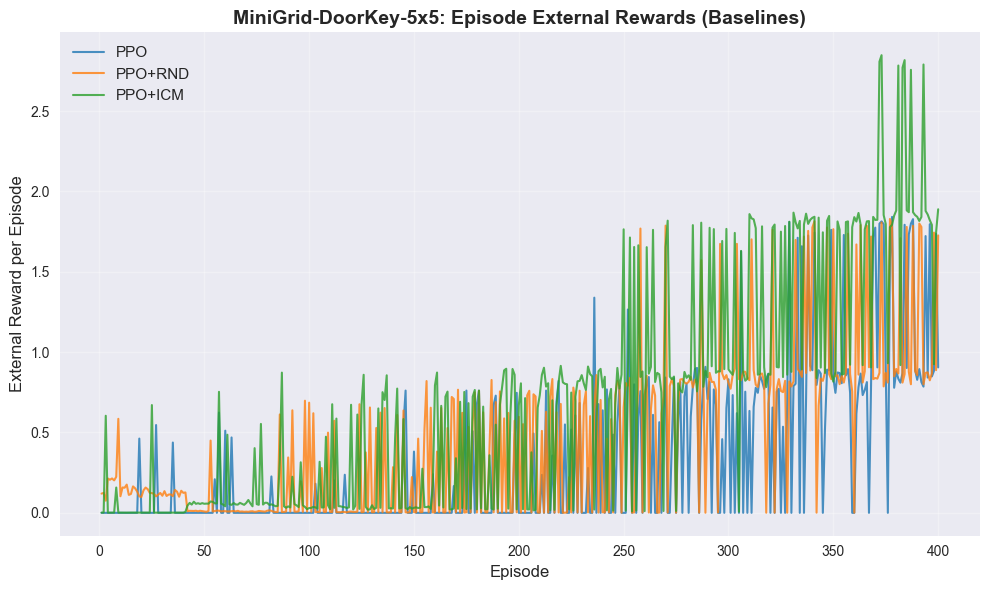


绘制 MiniGrid-DoorKey-5x5: Episode Intrinsic Rewards (Baselines)...


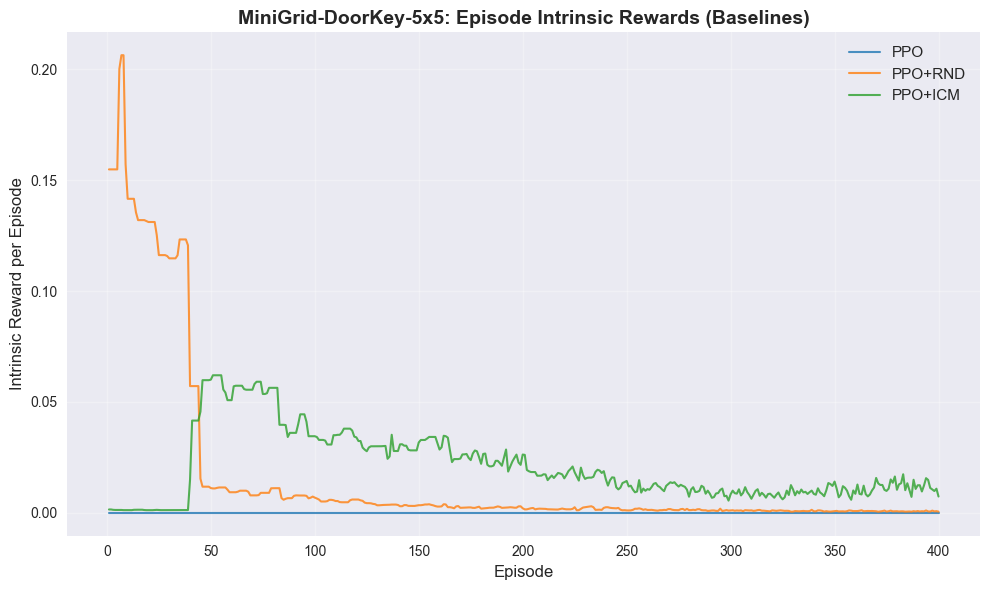


绘制 Total Reward (Cumulative) - Baselines...
  [OK] PPO: 400 个 episodes
  [OK] PPO+RND: 400 个 episodes
  [OK] PPO+ICM: 400 个 episodes


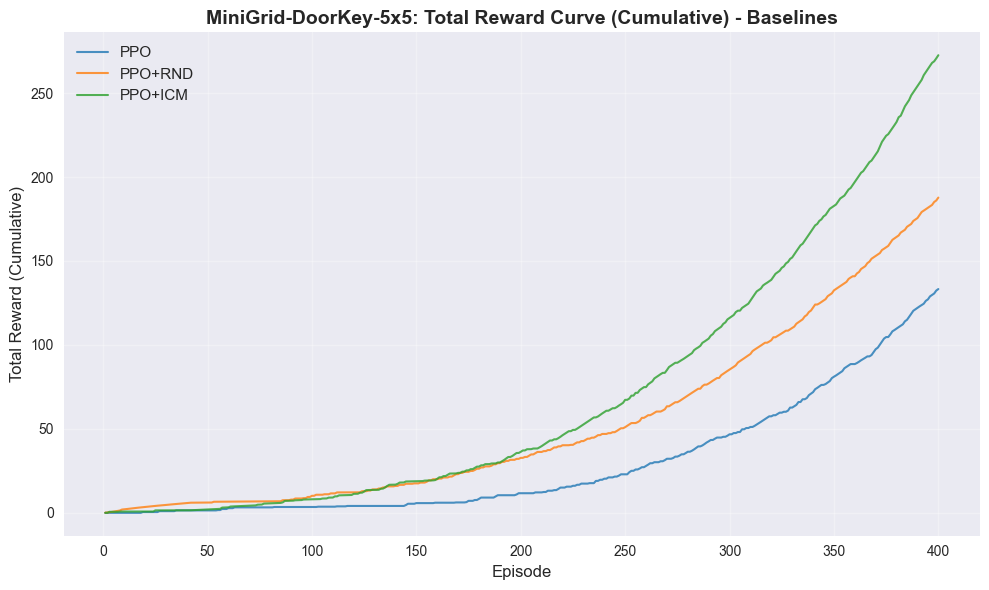

In [106]:
# ===== 单独绘制 Baselines 对比图：PPO, PPO+RND, PPO+ICM =====
# 只显示三个 baseline 方法，不包含 NS 和 BANS

if len(DATA) > 0:
    print("\n" + "=" * 60)
    print("绘制 Baselines 对比图: PPO, PPO+RND, PPO+ICM")
    print("=" * 60)
    
    # 筛选出 baselines
    baseline_names = ["PPO", "PPO+RND", "PPO+ICM"]
    baseline_data = {name: DATA[name] for name in baseline_names if name in DATA}
    
    if len(baseline_data) == 0:
        print("未找到任何 baseline 数据")
    else:
        print(f"找到 {len(baseline_data)} 个 baseline: {', '.join(baseline_data.keys())}")
        
        # ===== 将 step 数据转换为固定大小的 episode 数据（50 steps/episode）=====
        def convert_steps_to_episodes(step_data, steps_per_episode=50):
            """将 step-level 数据转换为固定大小的 episode 数据"""
            if not isinstance(step_data, np.ndarray):
                step_data = np.array(step_data)
            n_steps = len(step_data)
            n_episodes = n_steps // steps_per_episode
            episode_data = []
            for i in range(n_episodes):
                start_idx = i * steps_per_episode
                end_idx = min((i + 1) * steps_per_episode, n_steps)
                episode_reward = np.sum(step_data[start_idx:end_idx])
                episode_data.append(episode_reward)
            return np.array(episode_data)
        
        # 1. 绘制 Episode External Rewards
        print(f"\n绘制 MiniGrid-DoorKey-5x5: Episode External Rewards (Baselines)...")
        plt.figure(figsize=(10, 6))
        for name, data in baseline_data.items():
            step_rewards = get_data_field(data, "step_rewards")
            if step_rewards is None:
                print(f"  [WARN] {name} 中没有找到 step_rewards 字段")
                continue
            if not isinstance(step_rewards, np.ndarray):
                step_rewards = np.array(step_rewards)
            
            # 转换为固定大小的 episode 数据
            episode_rewards = convert_steps_to_episodes(step_rewards, steps_per_episode=50)
            x_data = np.arange(1, len(episode_rewards) + 1)
            color = color_map.get(name, None)
            plt.plot(x_data, episode_rewards, label=name, linewidth=1.5, alpha=0.8, color=color)
        plt.legend(fontsize=11)
        plt.grid(True, alpha=0.3)
        plt.xlabel("Episode", fontsize=12)
        plt.ylabel("External Reward per Episode", fontsize=12)
        plt.title("MiniGrid-DoorKey-5x5: Episode External Rewards (Baselines)", fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
        
        # 2. 绘制 Episode Intrinsic Rewards
        print(f"\n绘制 MiniGrid-DoorKey-5x5: Episode Intrinsic Rewards (Baselines)...")
        plt.figure(figsize=(10, 6))
        for name, data in baseline_data.items():
            # 对于 baselines，需要将 episode_intrinsic 转换为 step_intrinsic
            episode_intrinsic = data.get("episode_intrinsic")
            step_rewards = data.get("all_step_rewards")
            if episode_intrinsic is not None and step_rewards is not None:
                if len(episode_intrinsic) > 0 and np.any(episode_intrinsic != 0):
                    episode_lengths = data.get("episode_lengths")
                    if episode_lengths is not None and len(episode_lengths) > 0:
                        step_intrinsic = np.zeros(len(step_rewards))
                        current_step = 0
                        for i in range(len(episode_intrinsic)):
                            ep_len = int(episode_lengths[i])
                            end_step = min(current_step + ep_len, len(step_rewards))
                            if end_step > current_step:
                                step_intrinsic[current_step:end_step] = episode_intrinsic[i] / (end_step - current_step)
                            current_step = end_step
                    else:
                        steps_per_ep = len(step_rewards) // len(episode_intrinsic)
                        step_intrinsic = np.zeros(len(step_rewards))
                        for i in range(len(episode_intrinsic)):
                            start = i * steps_per_ep
                            end = min((i + 1) * steps_per_ep, len(step_rewards))
                            if end > start:
                                step_intrinsic[start:end] = episode_intrinsic[i] / (end - start)
                else:
                    step_intrinsic = np.zeros(len(step_rewards))
            else:
                step_intrinsic = np.zeros(len(data.get("all_step_rewards", [0])))
            
            if not isinstance(step_intrinsic, np.ndarray):
                step_intrinsic = np.array(step_intrinsic)
            
            # 转换为固定大小的 episode 数据
            episode_intrinsic = convert_steps_to_episodes(step_intrinsic, steps_per_episode=50)
            x_data = np.arange(1, len(episode_intrinsic) + 1)
            color = color_map.get(name, None)
            plt.plot(x_data, episode_intrinsic, label=name, linewidth=1.5, alpha=0.8, color=color)
        plt.legend(fontsize=11)
        plt.grid(True, alpha=0.3)
        plt.xlabel("Episode", fontsize=12)
        plt.ylabel("Intrinsic Reward per Episode", fontsize=12)
        plt.title("MiniGrid-DoorKey-5x5: Episode Intrinsic Rewards (Baselines)", fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
        
        # 3. 绘制累积总奖励曲线
        print(f"\n绘制 Total Reward (Cumulative) - Baselines...")
        plt.figure(figsize=(10, 6))
        for name, data in baseline_data.items():
            step_rewards = get_data_field(data, "step_rewards")
            if step_rewards is None:
                print(f"  [WARN] {name} 中没有找到 step_rewards 字段")
                continue
            if not isinstance(step_rewards, np.ndarray):
                step_rewards = np.array(step_rewards)
            
            # 转换为固定大小的 episode 数据
            episode_rewards = convert_steps_to_episodes(step_rewards, steps_per_episode=50)
            
            # 计算累积总奖励
            total_reward_curve = np.cumsum(episode_rewards)
            
            # x 轴：episode 编号
            x_data = np.arange(1, len(total_reward_curve) + 1)
            
            color = color_map.get(name, None)
            plt.plot(x_data, total_reward_curve, label=name, linewidth=1.5, alpha=0.8, color=color)
            print(f"  [OK] {name}: {len(total_reward_curve)} 个 episodes")
        
        plt.legend(fontsize=11)
        plt.grid(True, alpha=0.3)
        plt.xlabel("Episode", fontsize=12)
        plt.ylabel("Total Reward (Cumulative)", fontsize=12)
        plt.title("MiniGrid-DoorKey-5x5: Total Reward Curve (Cumulative) - Baselines", fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
        
else:
    print("\n未找到任何可用的数据")



为每个数据集绘制详细图表...

PPO


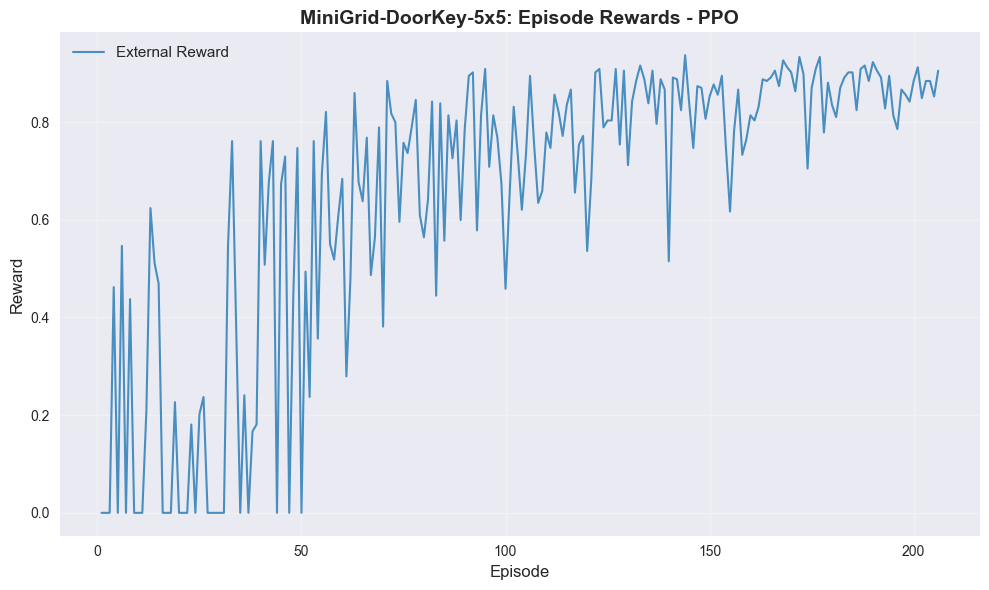

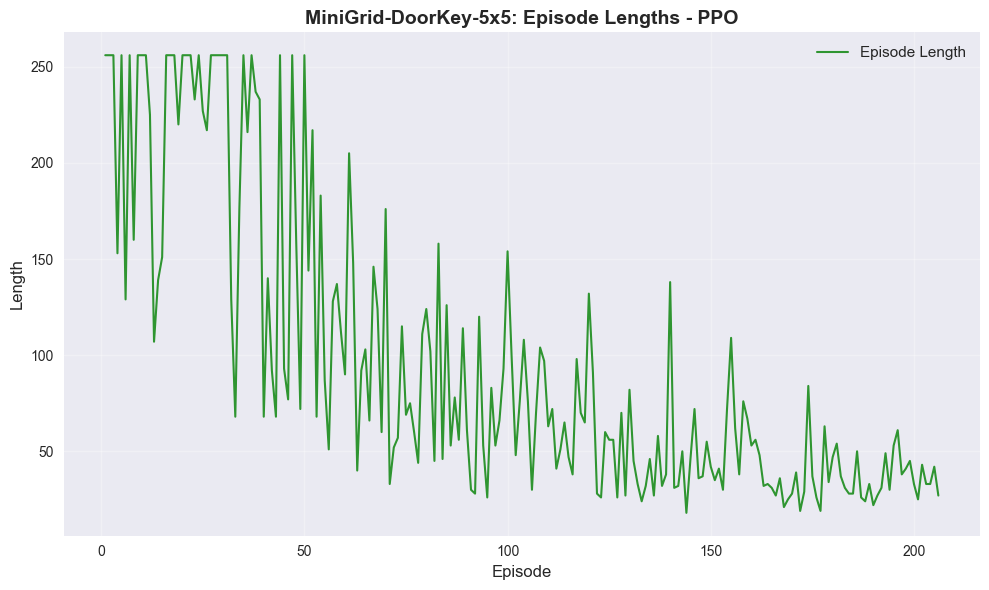


PPO+RND


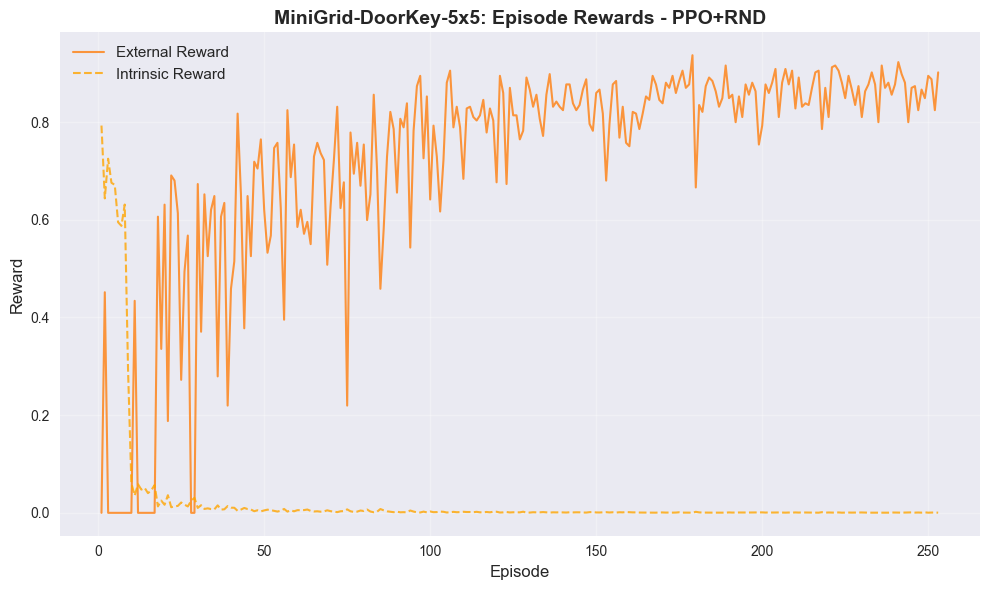

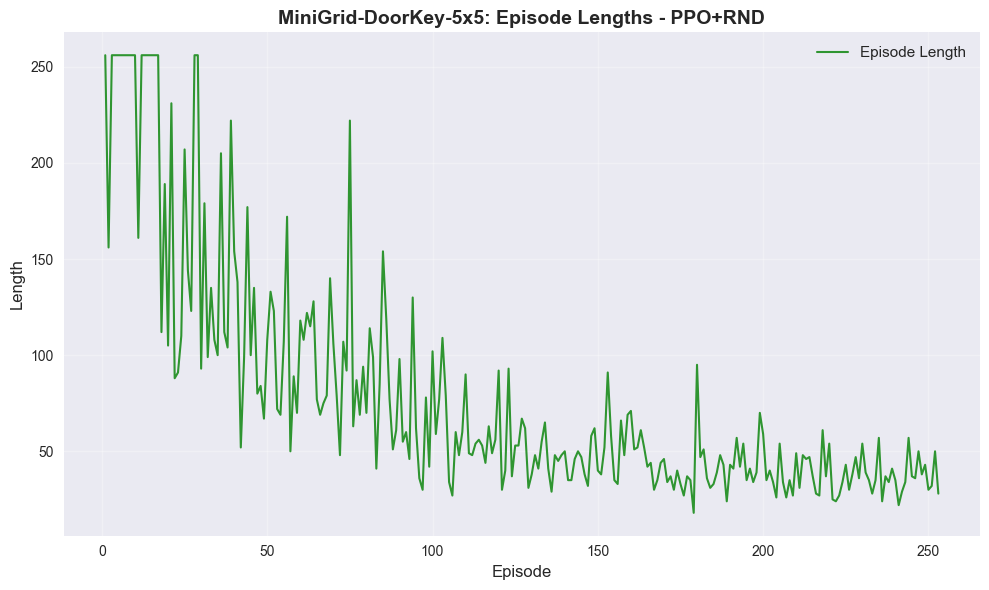


PPO+ICM


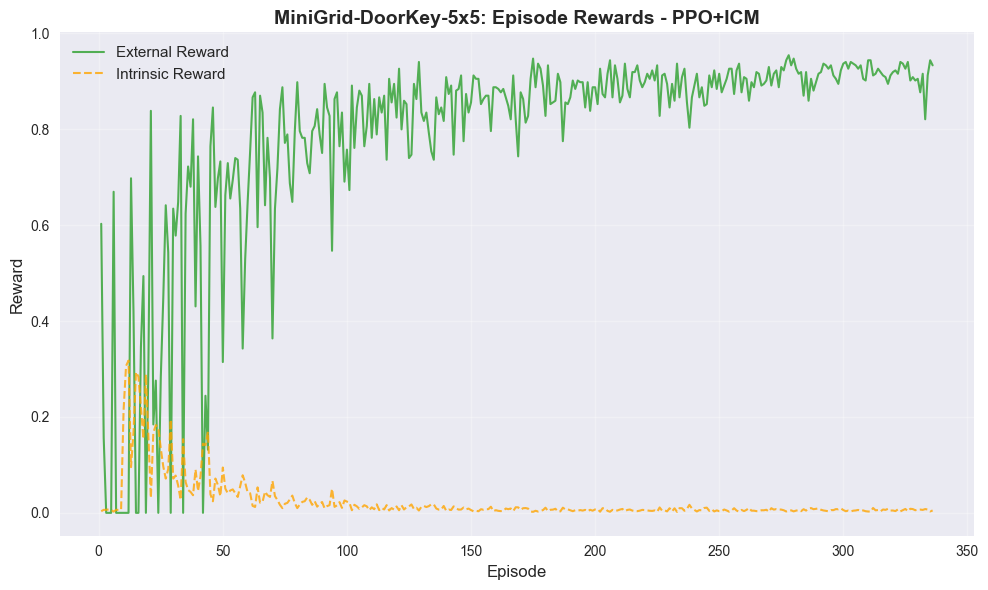

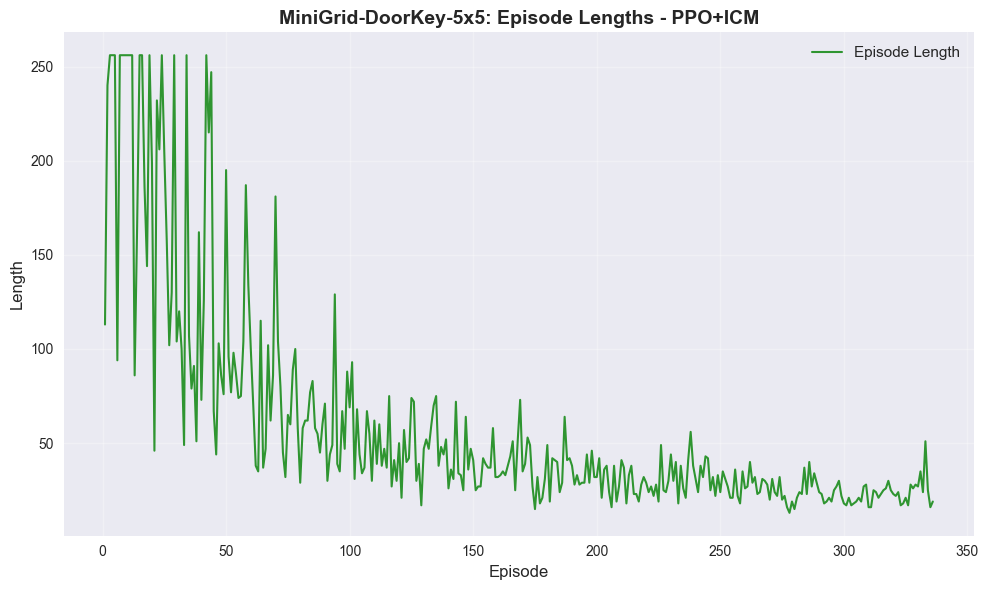


PPO+Novelty Search


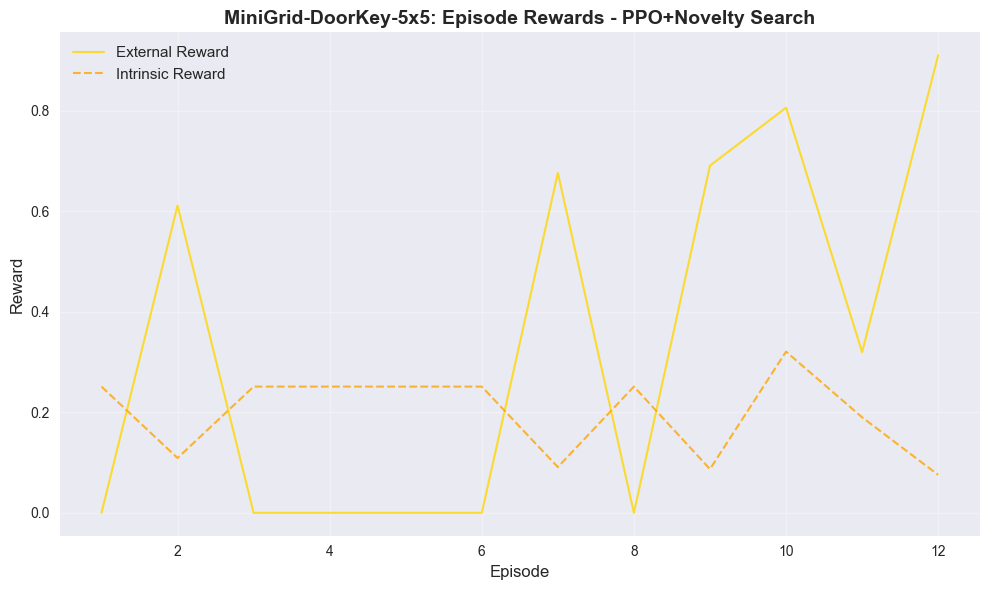


PPO+Boundary-Aware Novelty Search


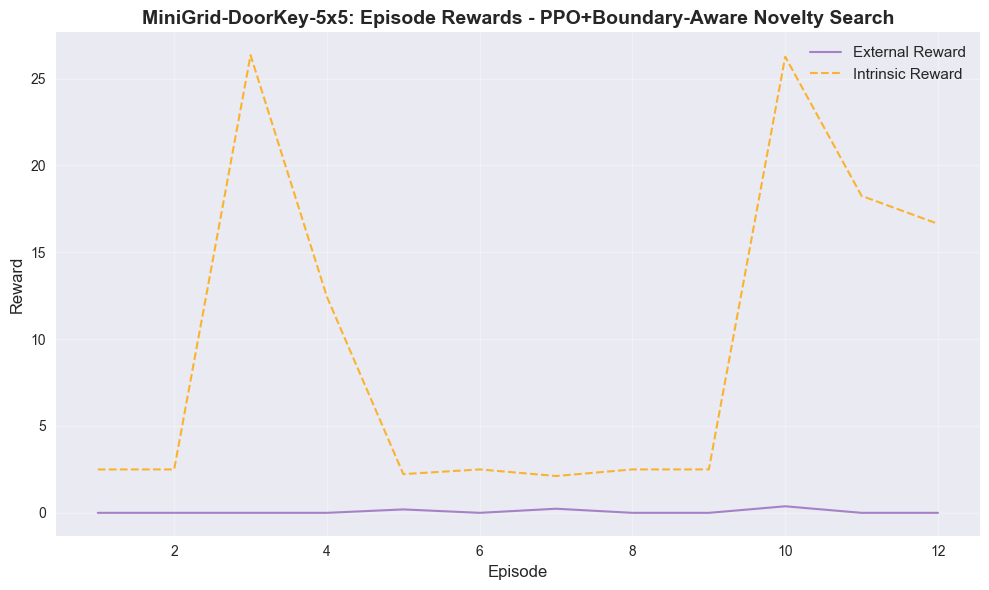

In [107]:
# ===== 为每个数据集单独绘制详细图表 =====

if len(DATA) > 0:
    print("\n" + "=" * 60)
    print("为每个数据集绘制详细图表...")
    print("=" * 60)
    
    for name, data in DATA.items():
        print(f"\n{'='*60}")
        print(f"{name}")
        print(f"{'='*60}")
        
        # 获取数据
        episode_rewards = get_data_field(data, "episode_rewards")
        episode_intrinsic = get_data_field(data, "episode_intrinsic")
        episode_lengths = get_data_field(data, "episode_lengths")
        
        if episode_rewards is None:
            print(f"  [WARN] {name} 中没有找到 episode_rewards")
            continue
        
        # 转换为 numpy array
        if not isinstance(episode_rewards, np.ndarray):
            episode_rewards = np.array(episode_rewards)
        if episode_intrinsic is not None and not isinstance(episode_intrinsic, np.ndarray):
            episode_intrinsic = np.array(episode_intrinsic)
        if episode_lengths is not None and not isinstance(episode_lengths, np.ndarray):
            episode_lengths = np.array(episode_lengths)
        
        # 绘制 External + Intrinsic Rewards 对比
        plt.figure(figsize=(10, 6))
        episodes = np.arange(1, len(episode_rewards) + 1)
        color = color_map.get(name, None)
        
        plt.plot(episodes, episode_rewards, label="External Reward", linewidth=1.5, alpha=0.8, color=color)
        
        if episode_intrinsic is not None and len(episode_intrinsic) > 0:
            # 只有当 intrinsic reward 不全为 0 时才显示
            if np.any(episode_intrinsic != 0):
                intrinsic_episodes = np.arange(1, len(episode_intrinsic) + 1)
                plt.plot(intrinsic_episodes, episode_intrinsic, label="Intrinsic Reward", 
                        linewidth=1.5, alpha=0.8, color="orange", linestyle='--')
        
        plt.legend(fontsize=11)
        plt.grid(True, alpha=0.3)
        plt.xlabel("Episode", fontsize=12)
        plt.ylabel("Reward", fontsize=12)
        plt.title(f"MiniGrid-DoorKey-5x5: Episode Rewards - {name}", fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
        
        # 绘制 Episode Lengths（如果有）
        if episode_lengths is not None and len(episode_lengths) > 0:
            plt.figure(figsize=(10, 6))
            length_episodes = np.arange(1, len(episode_lengths) + 1)
            plt.plot(length_episodes, episode_lengths, label="Episode Length", 
                    linewidth=1.5, alpha=0.8, color="green")
            plt.legend(fontsize=11)
            plt.grid(True, alpha=0.3)
            plt.xlabel("Episode", fontsize=12)
            plt.ylabel("Length", fontsize=12)
            plt.title(f"MiniGrid-DoorKey-5x5: Episode Lengths - {name}", fontsize=14, fontweight='bold')
            plt.tight_layout()
            plt.show()
else:
    print("\n未找到任何可用的数据")
